In [1]:
# EG L = 3，6 的结果不是想要的

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'lo

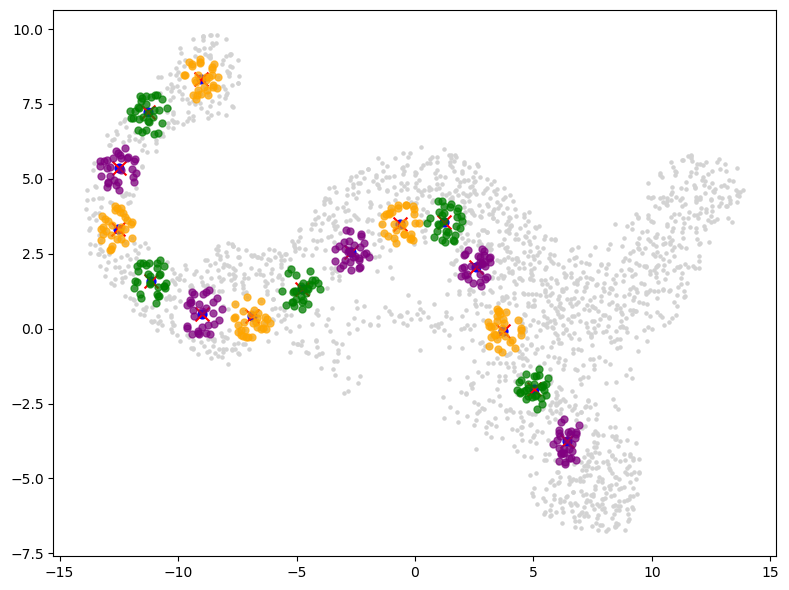

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

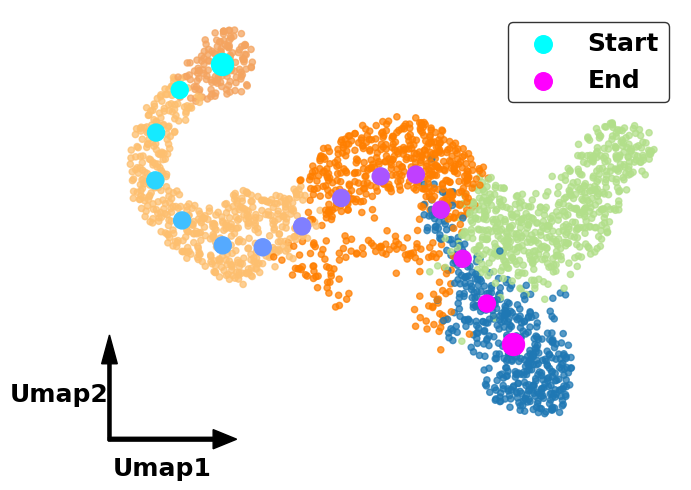

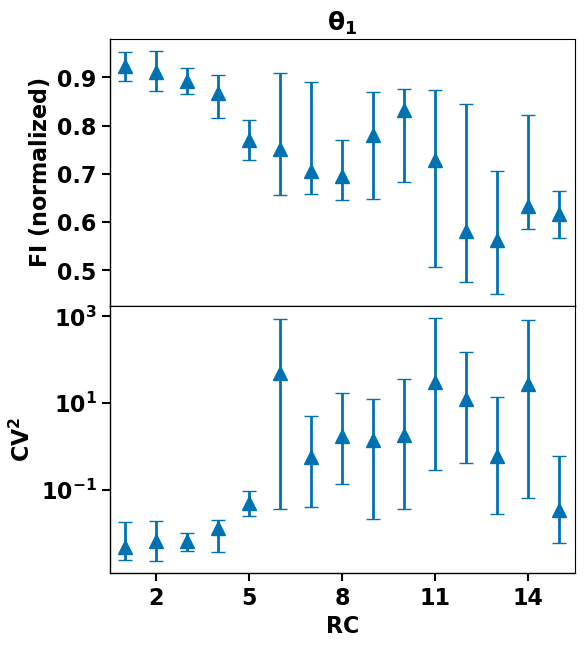

new_array.shape (15, 30, 3)
y: [4.8263525e-03 6.4485390e-03 6.4049154e-03 1.2996034e-02 4.8340667e-02
 4.8943062e+01 5.5476224e-01 1.6848538e+00 1.4003255e+00 1.8392752e+00
 3.0772757e+01 1.2317414e+01 6.1046672e-01 2.6935352e+01 3.4205906e-02]
max_vals: [1.7829029e-02 1.8633883e-02 9.8189814e-03 2.0060556e-02 9.4235122e-02
 8.6843622e+02 5.0109210e+00 1.6965155e+01 1.2538547e+01 3.5801044e+01
 8.9489606e+02 1.4604599e+02 1.3535188e+01 8.0510931e+02 6.1080921e-01]
min_vals: [0.00235997 0.00222696 0.00375904 0.00366663 0.02465294 0.03638835
 0.04052642 0.13162668 0.02077151 0.03515838 0.2771151  0.4175991
 0.02770971 0.06263747 0.00595184]
error: [[2.46638572e-03 4.22157906e-03 2.64587463e-03 9.32940561e-03
  2.36877240e-02 4.89066734e+01 5.14235854e-01 1.55322707e+00
  1.37955403e+00 1.80411685e+00 3.04956417e+01 1.18998156e+01
  5.82756996e-01 2.68727150e+01 2.82540694e-02]
 [1.30026769e-02 1.21853445e-02 3.41406604e-03 7.06452224e-03
  4.58944552e-02 8.19493164e+02 4.45615864e+00 1.5

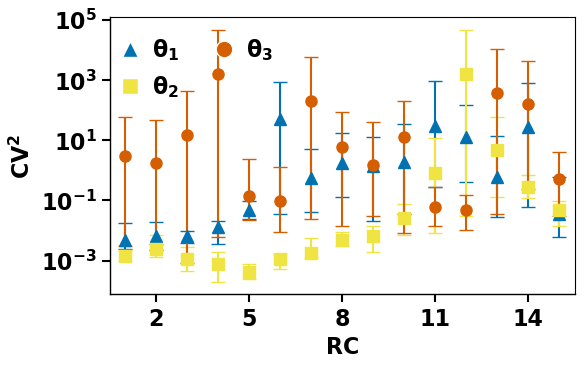

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

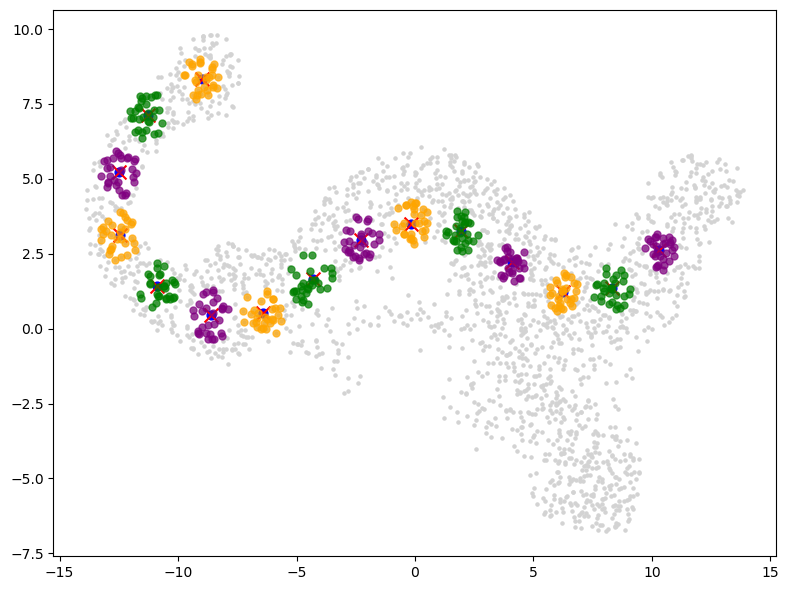

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

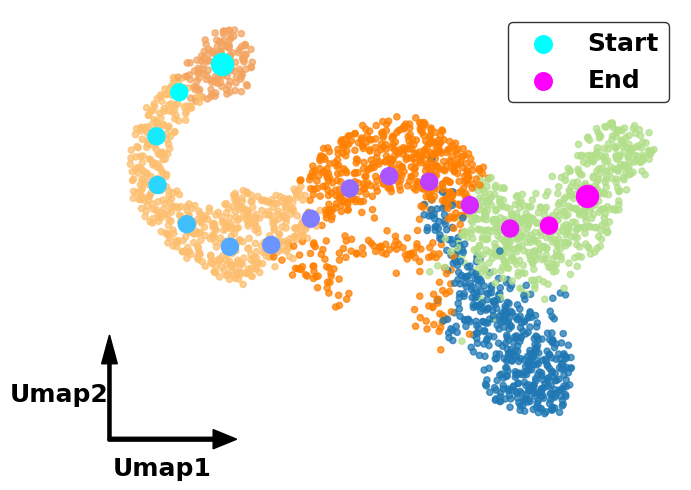

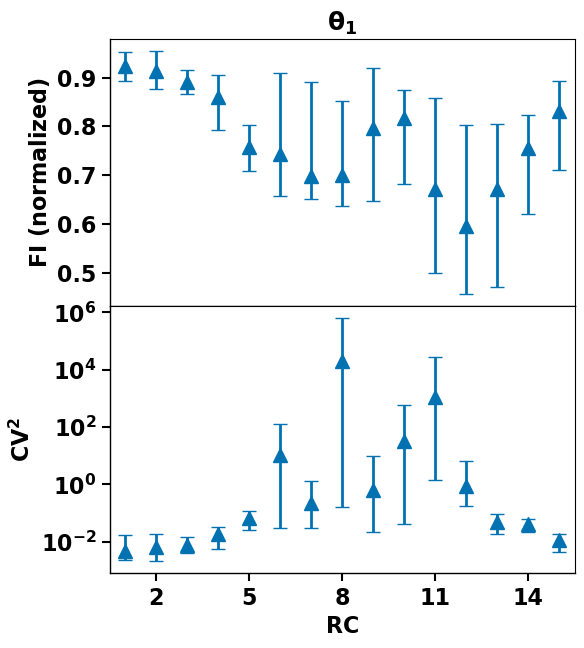

new_array.shape (15, 30, 3)
y: [4.8263529e-03 6.5026861e-03 7.7020507e-03 1.8682666e-02 6.5736294e-02
 1.0548349e+01 2.2014187e-01 2.0730254e+04 6.3153261e-01 3.2550343e+01
 1.0983540e+03 8.5272378e-01 4.7587864e-02 4.2045057e-02 1.1707548e-02]
max_vals: [1.78290308e-02 1.80533789e-02 1.52103826e-02 3.26303579e-02
 1.19032815e-01 1.23699638e+02 1.35208428e+00 6.20716000e+05
 9.73518372e+00 5.75842590e+02 2.84814844e+04 6.36844778e+00
 9.44583416e-02 6.03457093e-02 1.81544144e-02]
min_vals: [0.00235997 0.00211231 0.00395335 0.00562212 0.02654355 0.03083538
 0.03137817 0.16151255 0.02172147 0.04167803 1.3956823  0.17417997
 0.01848622 0.02127709 0.00439402]
error: [[2.46638618e-03 4.39037709e-03 3.74869723e-03 1.30605465e-02
  3.91927436e-02 1.05175142e+01 1.88763708e-01 2.07300918e+04
  6.09811127e-01 3.25086632e+01 1.09695837e+03 6.78543806e-01
  2.91016400e-02 2.07679626e-02 7.31352717e-03]
 [1.30026778e-02 1.15506928e-02 7.50833191e-03 1.39476918e-02
  5.32965213e-02 1.13151291e+02 1

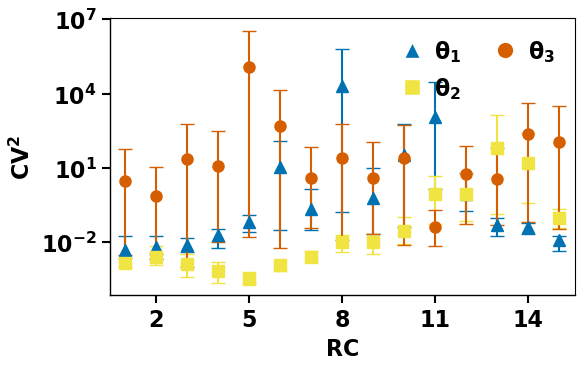

[k_nei, K, L] = [10, 3, 6]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'lo

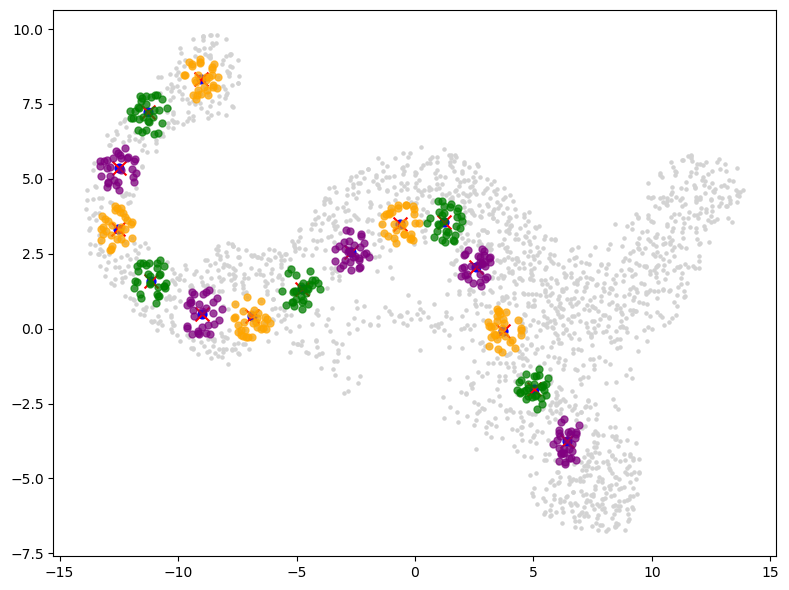

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

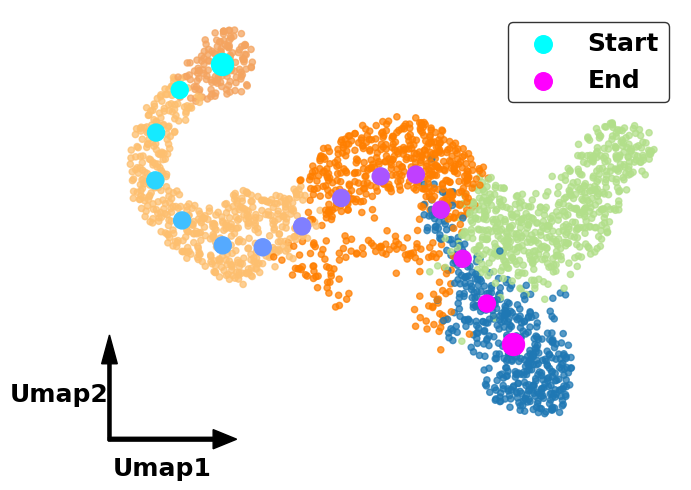

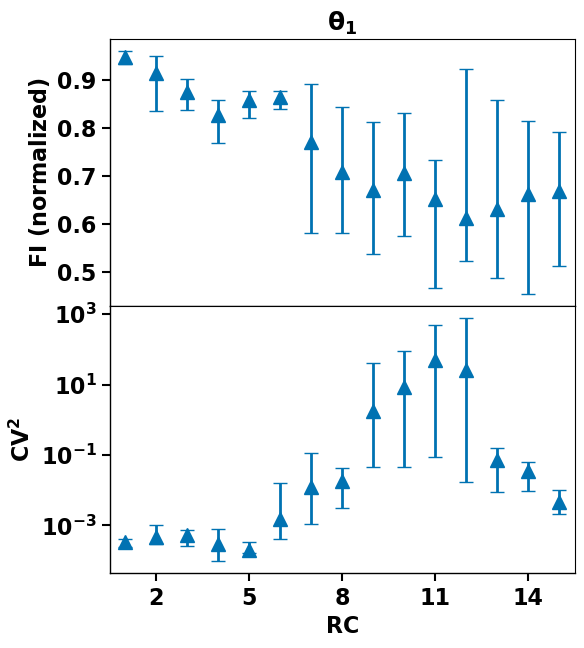

new_array.shape (15, 30, 3)
y: [3.2602798e-04 4.5026123e-04 5.2898366e-04 2.9797808e-04 2.0464433e-04
 1.4675439e-03 1.1936201e-02 1.8705813e-02 1.7883903e+00 8.4457235e+00
 4.8667919e+01 2.5770863e+01 7.1339674e-02 3.5617746e-02 4.4379737e-03]
max_vals: [4.16419993e-04 1.04617956e-03 7.39123090e-04 7.77046953e-04
 3.40303435e-04 1.57736838e-02 1.12455614e-01 4.28884849e-02
 4.21766129e+01 8.73085175e+01 4.84629639e+02 7.58877014e+02
 1.56656444e-01 6.08543195e-02 9.83278733e-03]
min_vals: [2.4366709e-04 2.8688720e-04 2.4961808e-04 9.5706906e-05 1.6415374e-04
 4.1377128e-04 1.0587871e-03 3.1616448e-03 4.5103099e-02 4.5588557e-02
 8.7735884e-02 1.6874475e-02 8.7903300e-03 9.1129951e-03 2.0610169e-03]
error: [[8.2360886e-05 1.6337403e-04 2.7936557e-04 2.0227119e-04 4.0490588e-05
  1.0537726e-03 1.0877414e-02 1.5544169e-02 1.7432872e+00 8.4001350e+00
  4.8580185e+01 2.5753988e+01 6.2549345e-02 2.6504751e-02 2.3769569e-03]
 [9.0392015e-05 5.9591833e-04 2.1013943e-04 4.7906887e-04 1.3565911

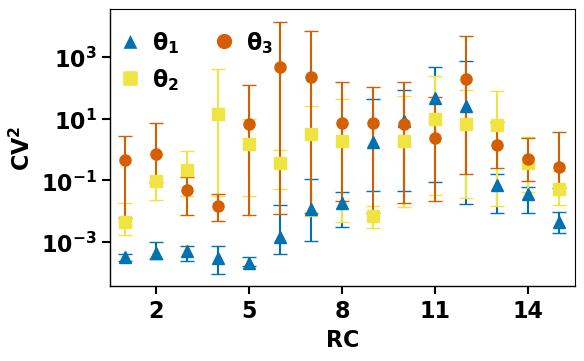

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

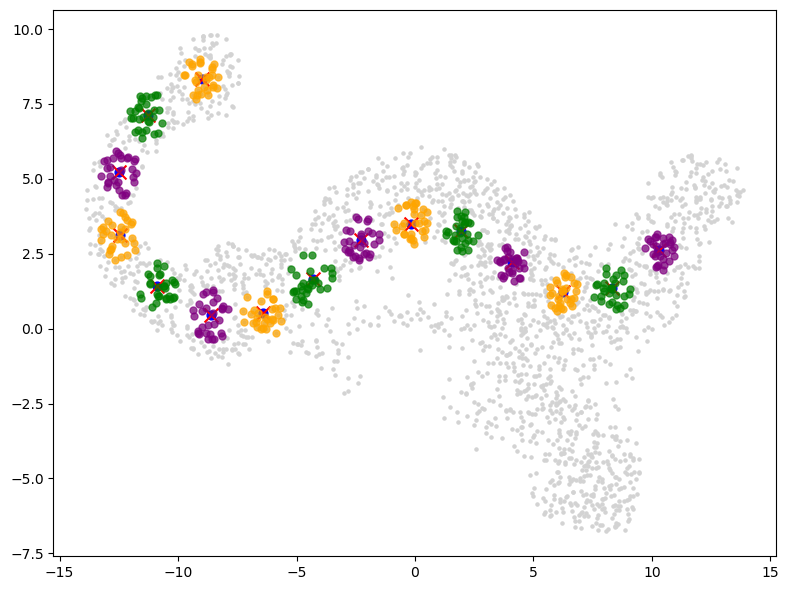

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

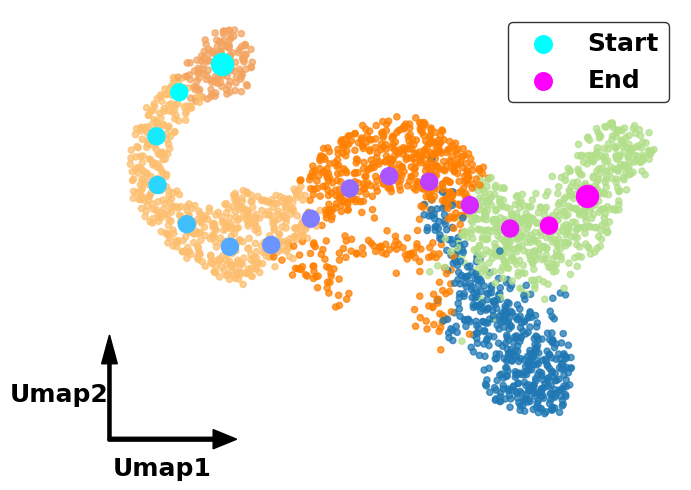

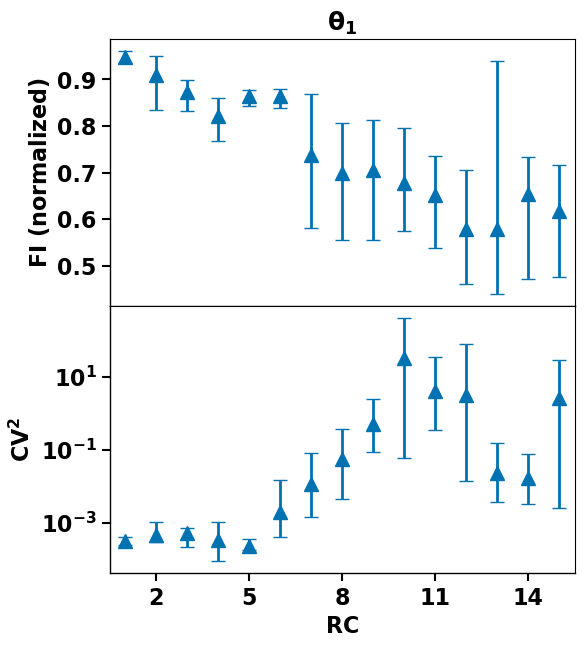

new_array.shape (15, 30, 3)
y: [3.2602798e-04 4.6049801e-04 5.1921181e-04 3.4403798e-04 2.3663796e-04
 1.9565942e-03 1.2059475e-02 5.7659626e-02 5.2377582e-01 3.4501148e+01
 4.2285905e+00 3.2547836e+00 2.3068093e-02 1.6767466e-02 2.7617671e+00]
max_vals: [4.1641999e-04 1.0440743e-03 7.1662228e-04 1.0859331e-03 3.6391336e-04
 1.5011058e-02 8.2291134e-02 3.7689483e-01 2.5795345e+00 4.0961722e+02
 3.6582775e+01 8.0272018e+01 1.5791568e-01 8.0247723e-02 2.9727943e+01]
min_vals: [2.4366709e-04 2.9301547e-04 2.2390297e-04 8.9872236e-05 1.8458154e-04
 4.1967581e-04 1.4702136e-03 4.5033554e-03 8.7087132e-02 5.9271671e-02
 3.5543829e-01 1.4405098e-02 3.7435896e-03 3.3641015e-03 2.5595652e-03]
error: [[8.2360886e-05 1.6748253e-04 2.9530883e-04 2.5416573e-04 5.2056421e-05
  1.5369183e-03 1.0589262e-02 5.3156272e-02 4.3668869e-01 3.4441875e+01
  3.8731523e+00 3.2403786e+00 1.9324504e-02 1.3403365e-02 2.7592075e+00]
 [9.0392015e-05 5.8357627e-04 1.9741047e-04 7.4189506e-04 1.2727540e-04
  1.3054464

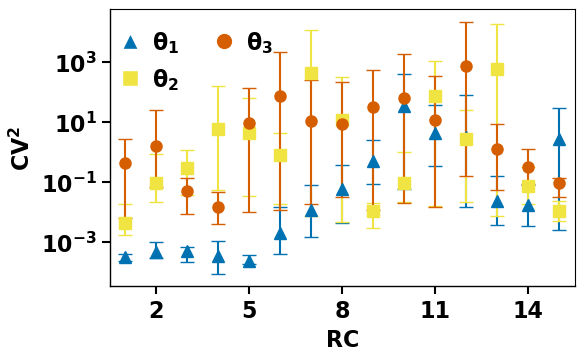

[k_nei, K, L] = [10, 3, 10]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'l

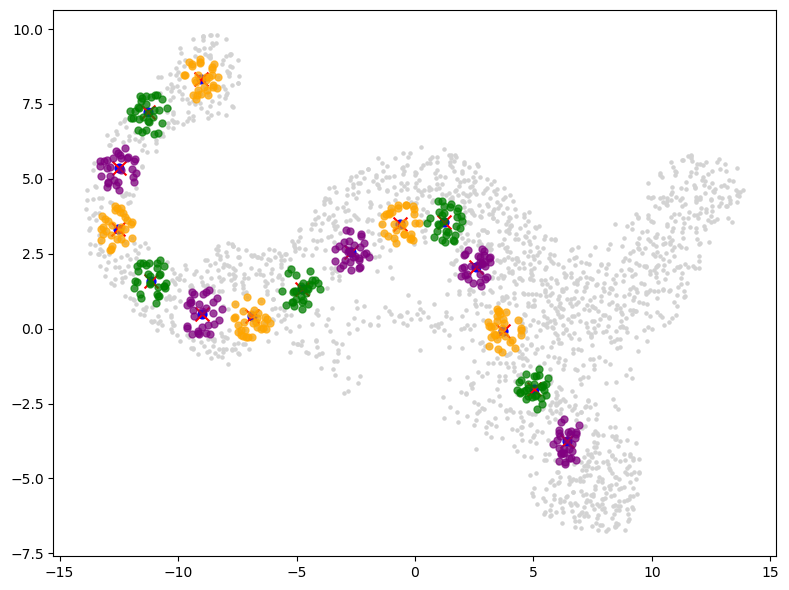

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

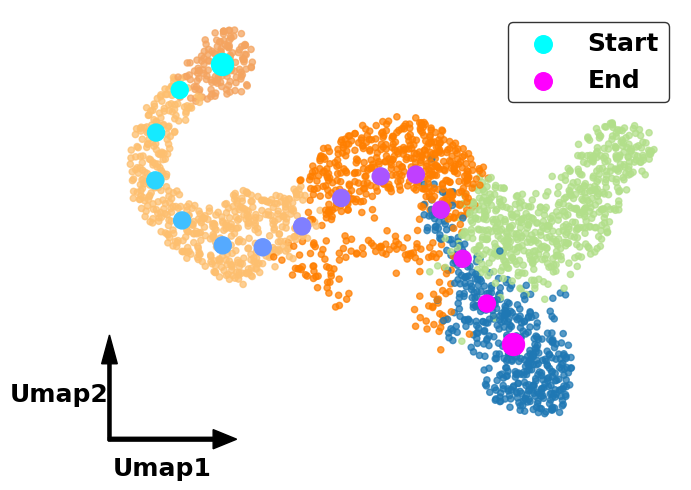

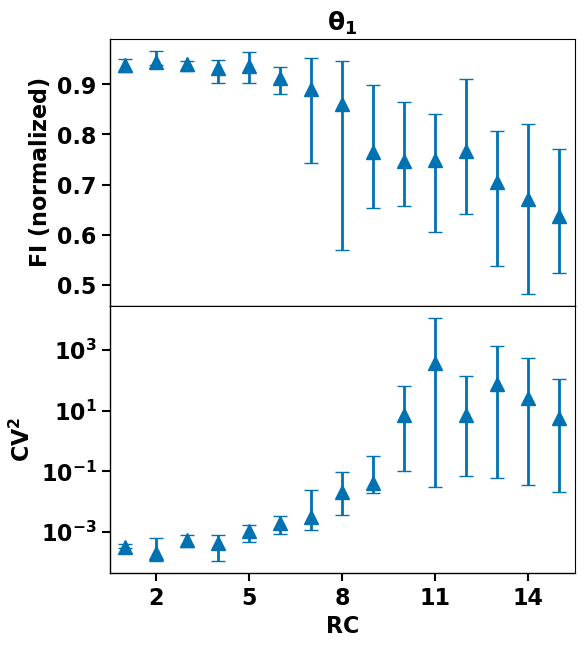

new_array.shape (15, 30, 3)
y: [3.2578473e-04 2.0245796e-04 5.4621865e-04 4.3653429e-04 1.1160460e-03
 2.0184261e-03 3.2594099e-03 2.1187739e-02 4.2673070e-02 7.0434198e+00
 3.6971545e+02 7.4319577e+00 7.4692696e+01 2.6242704e+01 5.6729288e+00]
max_vals: [3.9885045e-04 6.2197942e-04 8.1119098e-04 8.3919486e-04 1.7208209e-03
 3.5197975e-03 2.3689801e-02 9.6832268e-02 3.1285834e-01 6.2748299e+01
 1.0915379e+04 1.3366544e+02 1.3765579e+03 5.3701172e+02 1.1105139e+02]
min_vals: [0.0003037  0.00011188 0.00032774 0.00011619 0.00049336 0.00086357
 0.00119205 0.00358582 0.01985473 0.10196272 0.03007874 0.07288484
 0.06213023 0.03475014 0.0208538 ]
error: [[2.20858492e-05 9.05756096e-05 2.18473724e-04 3.20343912e-04
  6.22690015e-04 1.15485676e-03 2.06735870e-03 1.76019147e-02
  2.28183400e-02 6.94145727e+00 3.69685364e+02 7.35907269e+00
  7.46305618e+01 2.62079544e+01 5.65207481e+00]
 [7.30657193e-05 4.19521471e-04 2.64972332e-04 4.02660575e-04
  6.04774919e-04 1.50137139e-03 2.04303917e-02 7.

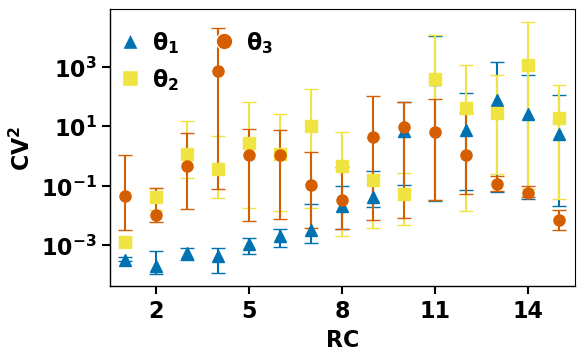

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

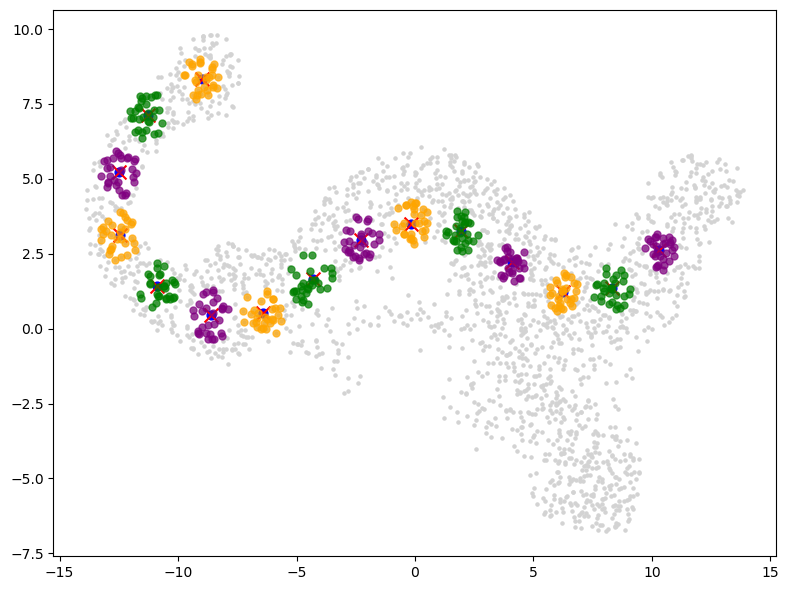

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

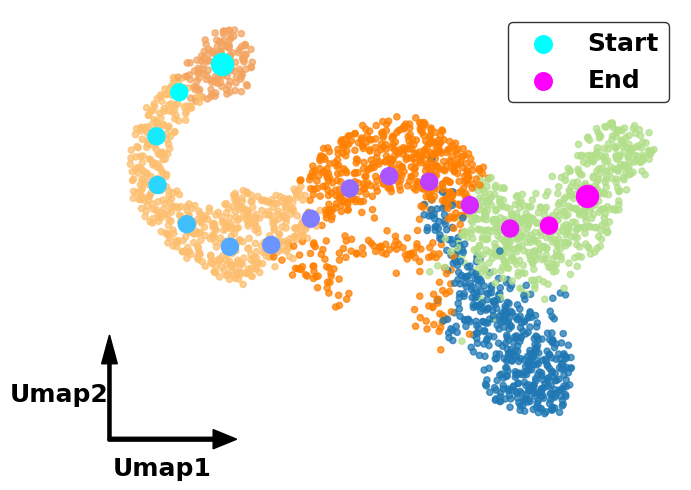

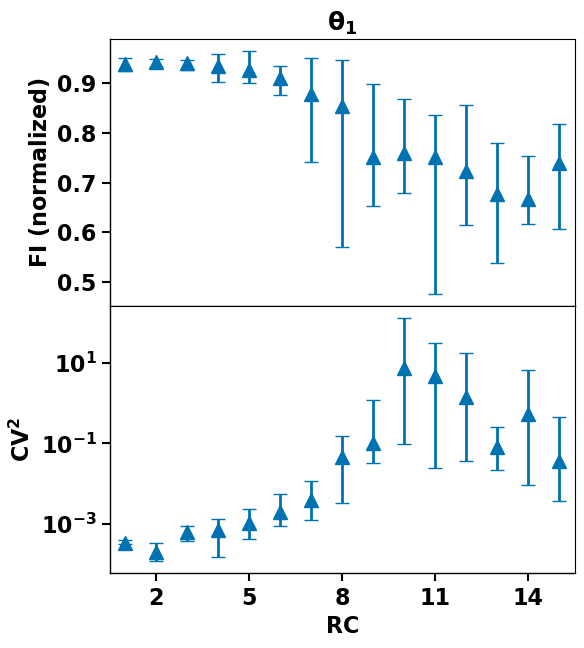

new_array.shape (15, 30, 3)
y: [3.25784727e-04 1.94712833e-04 6.21016079e-04 7.13685527e-04
 1.03121239e-03 1.90657354e-03 3.86677682e-03 4.49045189e-02
 1.02169566e-01 7.34802723e+00 4.69279575e+00 1.46471953e+00
 8.19154084e-02 5.45667708e-01 3.62109803e-02]
max_vals: [3.9885045e-04 3.3827711e-04 8.9771202e-04 1.3209989e-03 2.2552228e-03
 5.4830066e-03 1.1423173e-02 1.5094841e-01 1.2269514e+00 1.2940314e+02
 3.1531496e+01 1.7499008e+01 2.6170117e-01 6.6761727e+00 4.6234703e-01]
min_vals: [0.0003037  0.00011647 0.00037304 0.00014736 0.00041354 0.00087006
 0.00123792 0.0033241  0.03184358 0.09686466 0.02411447 0.03615724
 0.02173486 0.00892899 0.00365891]
error: [[2.2085849e-05 7.8239085e-05 2.4797369e-04 5.6632352e-04 6.1766763e-04
  1.0365185e-03 2.6288531e-03 4.1580424e-02 7.0325986e-02 7.2511625e+00
  4.6686811e+00 1.4285623e+00 6.0180549e-02 5.3673869e-01 3.2552067e-02]
 [7.3065719e-05 1.4356428e-04 2.7669594e-04 6.0731336e-04 1.2240104e-03
  3.5764331e-03 7.5563965e-03 1.0604389e

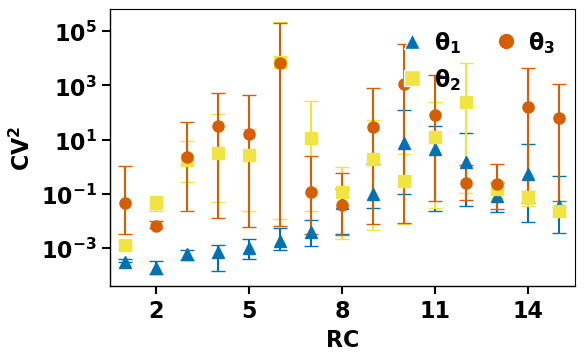

[k_nei, K, L] = [10, 3, 15]
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'l

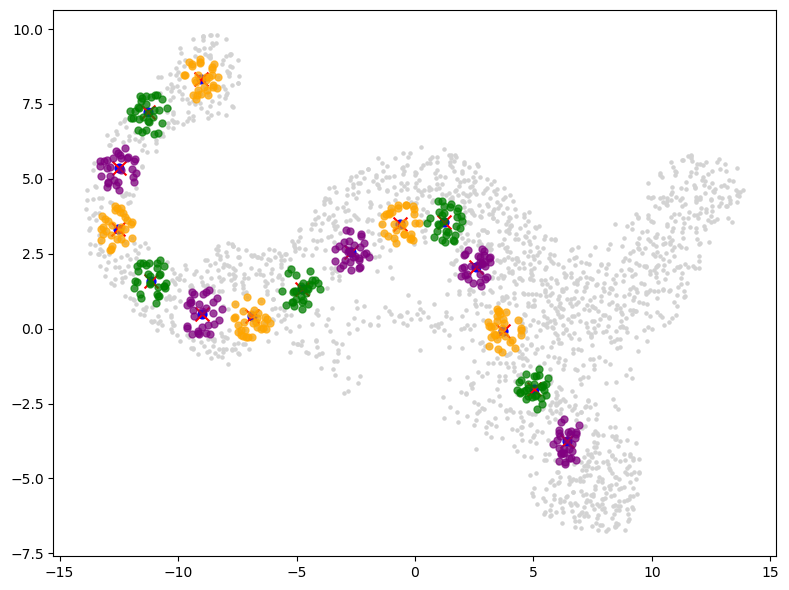

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

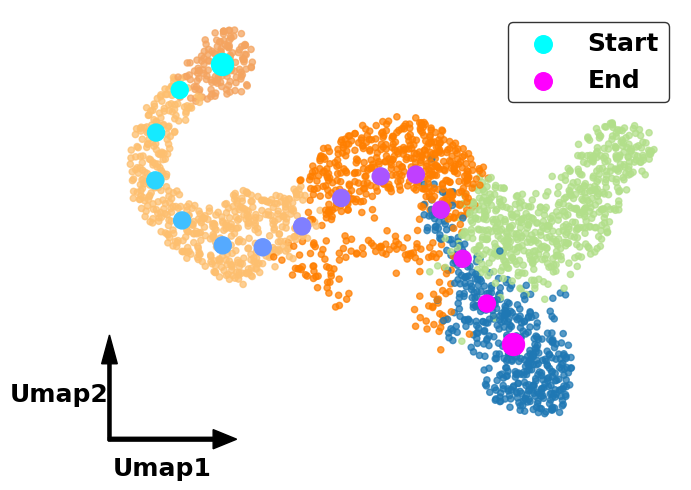

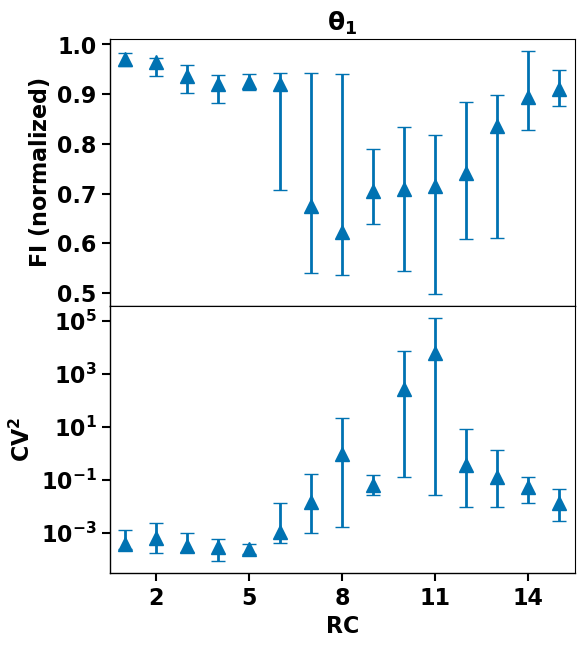

new_array.shape (15, 30, 3)
y: [3.8532395e-04 6.2370871e-04 3.0998341e-04 2.8630422e-04 2.3161898e-04
 1.0673405e-03 1.4232753e-02 9.6644026e-01 6.4669289e-02 2.7444763e+02
 6.0437842e+03 3.6690775e-01 1.2628073e-01 5.4044224e-02 1.3129250e-02]
max_vals: [1.29019958e-03 2.35088333e-03 9.22557840e-04 5.62708243e-04
 3.57780402e-04 1.26120653e-02 1.63494855e-01 2.18875103e+01
 1.51439607e-01 7.49520312e+03 1.27480859e+05 7.95525026e+00
 1.37915611e+00 1.23665035e-01 4.42889631e-02]
min_vals: [2.4610196e-04 1.7578433e-04 1.9092597e-04 8.3081191e-05 1.5249064e-04
 4.1564685e-04 9.2246581e-04 1.5945070e-03 2.6458146e-02 1.2844951e-01
 2.6664825e-02 9.1384398e-03 9.6199317e-03 1.3715342e-02 2.8195276e-03]
error: [[1.39221986e-04 4.47924365e-04 1.19057440e-04 2.03223026e-04
  7.91283383e-05 6.51693670e-04 1.33102871e-02 9.64845777e-01
  3.82111445e-02 2.74319183e+02 6.04375732e+03 3.57769310e-01
  1.16660796e-01 4.03288826e-02 1.03097223e-02]
 [9.04875633e-04 1.72717462e-03 6.12574397e-04 2.7

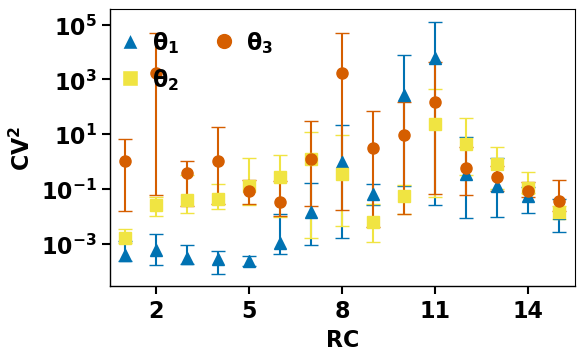

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 2322 × 514
    obs: 'day', 'proliferation', 'G2M_score', 'S_score', 'phase', 'clusters_coarse', 'clusters', 'clusters_fine', 'louvain_Alpha', 'louvain_Beta', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'root_cells', 'end_points', 'velocity_pseudotime'
    var: 'highly_variable_genes', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'clusters_colors', 'clusters_fine_colors', 'log1p', 'louvain_Alpha_colors', 'louvain_Beta_colors', 'neighb

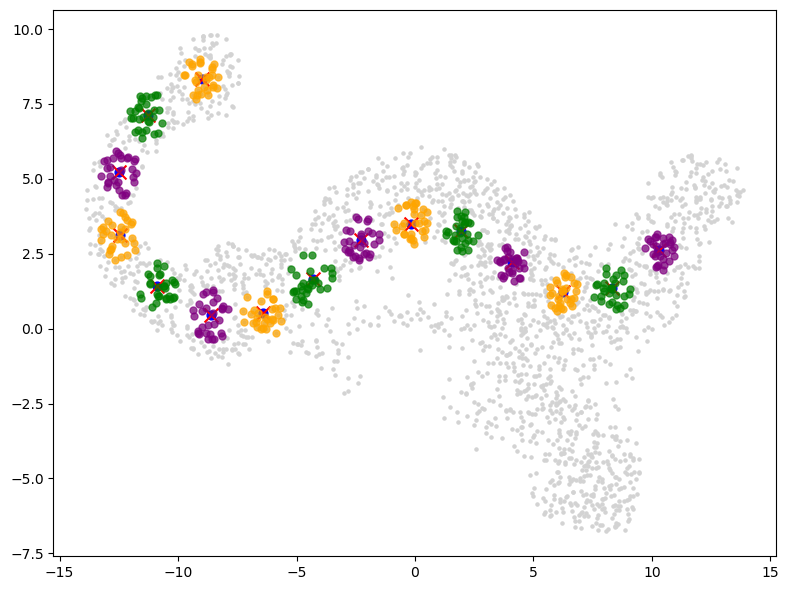

用的color_dict是： {'Ngn3 low EP': '#f4a460', 'Ngn3 high EP': '#fdbf6f', 'Fev+': '#ff7f00', 'Beta': '#b2df8a', 'Alpha': '#1f78b4'}
用的celltype_colors是： ['#ff7f00', '#1f78b4', '#fdbf6f', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#f4a460', '#ff7f00', '#b2df8a', '#ff7f00', '#1f78b4', '#1f78b4', '#b2df8a', '#b2df8a', '#f4a460', '#b2df8a', '#1f78b4', '#ff7f00', '#ff7f00', '#b2df8a', '#1f78b4', '#b2df8a', '#1f78b4', '#b2df8a', '#b2df8a', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#fdbf6f', '#b2df8a', '#ff7f00', '#fdbf6f', '#ff7f00', '#fdbf6f', '#fdbf6f', '#b2df8a', '#fdbf6f', '#b2df8a', '#b2df8a', '#1f78b4', '#1f78b4', '#ff7f00', '#1f78b4', '#1f78b4', '#ff7f00', '#b2df8a', '#f4a460', '#1f78b4', '#b2df8a', '#fdbf6f', '#b2df8a', '#fdbf6f', '#ff7f00', '#1f78b4', '#f4a460', '#fdbf6f', '#fdbf6f', '#ff7f00', '#b2df8a', '#1f78b4', '#f4a460', '#b2df8a', '#ff7f00', '#1f7

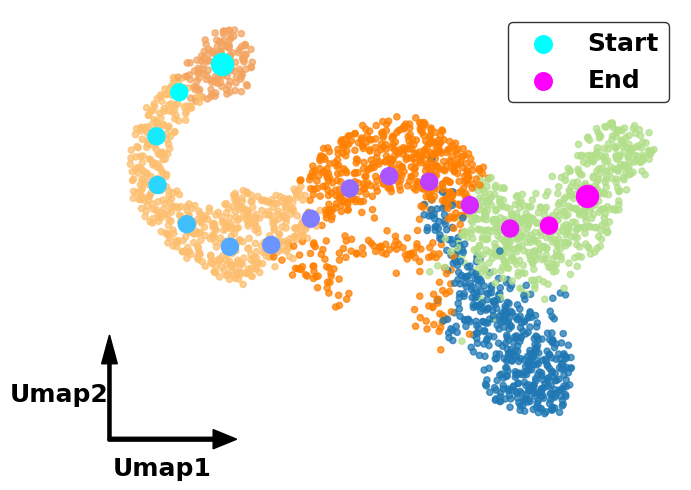

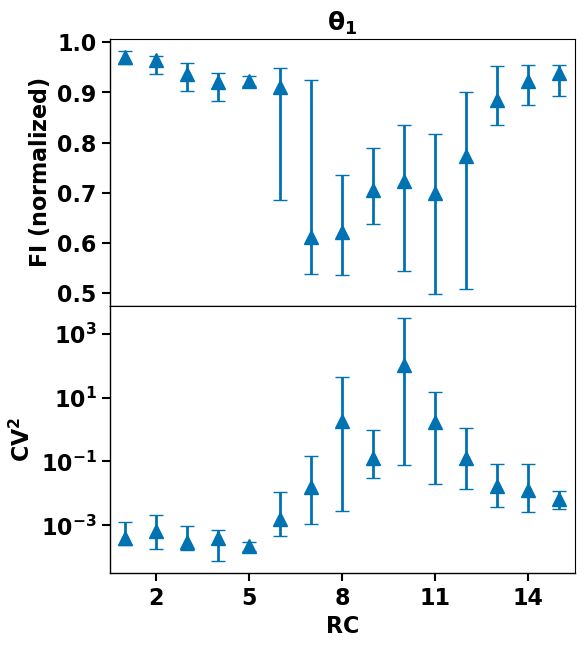

new_array.shape (15, 30, 3)
y: [3.85323918e-04 6.63408719e-04 3.02019180e-04 3.87134991e-04
 2.23195166e-04 1.61486317e-03 1.55306505e-02 1.82672954e+00
 1.32160917e-01 1.08876595e+02 1.69723463e+00 1.26279876e-01
 1.68616418e-02 1.31571833e-02 6.56082807e-03]
max_vals: [1.29019958e-03 2.12170463e-03 9.47627821e-04 7.33316003e-04
 3.05274036e-04 1.12062972e-02 1.49266735e-01 4.54480743e+01
 9.85794246e-01 3.04563818e+03 1.48059778e+01 1.08683252e+00
 8.31818581e-02 8.52331445e-02 1.15497485e-02]
min_vals: [2.4610196e-04 1.8082811e-04 1.6754867e-04 7.5101867e-05 1.5033616e-04
 4.6545881e-04 1.1116228e-03 2.7913596e-03 3.0676149e-02 7.5627081e-02
 1.9448575e-02 1.3227303e-02 3.6396768e-03 2.5455146e-03 3.1272238e-03]
error: [[1.39221956e-04 4.82580625e-04 1.34470509e-04 3.12033109e-04
  7.28590094e-05 1.14940433e-03 1.44190276e-02 1.82393813e+00
  1.01484768e-01 1.08800964e+02 1.67778611e+00 1.13052577e-01
  1.32219652e-02 1.06116682e-02 3.43360426e-03]
 [9.04875691e-04 1.45829585e-03 6.

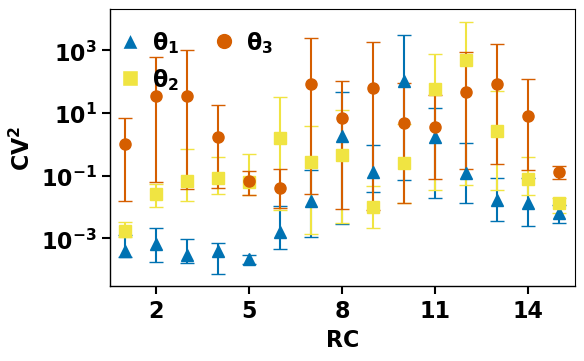

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]
# L_list = [6]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    data_name = "EG_ab_bin"

    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"
    [pca_dim, k_rc, d_pca, nrc] = [50, 30, 10, 10]
    clusters_name = "clusters"
    root_cluster = "Ngn3 low EP"
    loc_path_graph = 'upper right'
    basis = "umap"

    branch = [np.array(['Ngn3 low EP', 'Ngn3 high EP', 'Fev+', 'Alpha']), 
            np.array(['Ngn3 low EP', 'Ngn3 high EP', 'Fev+', 'Beta']) ]

    for t_list in (branch):

        branch_name = t_list[-1]
        adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
        adata = adata0.copy()
        scv.pp.pca(adata, n_comps=pca_dim)
        scv.pp.neighbors(adata, n_neighbors=k_nei)
        scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
        scv.tl.velocity(adata)
        print(adata)

        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        # cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=10)            
        # average_path = np.array(adata[nearest_cell].obsm["X_umap"])
        for nrc in [15]:
            average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}.npy') 
            print("average_path.shape", average_path.shape)
            cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, n_nei = k_rc, rc_distance= "X_umap")
            # cell_arr是每个RC point处选出的细胞的索引。

            # fig = sc.pl.embedding(
            #     adata,
            #     # color=[clusters_name, "paga"],
            #     color=[clusters_name],
            #     basis="pca",
            #     color_map=cmap,
            #     return_fig=True
            # )

            X_pca = adata.obsm['X_pca']
            row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
            col = adata.uns['neighbors']['indices'].flatten()
            w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
            adj_val = np.ones(col.shape)
            A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            A = A_mat
            W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            dc=np.mean(w_val)
            cell_nei=adata.uns['neighbors']['indices']
            nei_w=[]
            rho_arr=[]
            for ni in adata.uns['neighbors']['indices']:
                dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
                rho=np.sum(np.exp(-dij**2/dc**2))
                nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
                rho_arr.append(rho)
                
            rho_arr=np.array(rho_arr)/np.amax(rho_arr)
            nei_w=np.array(nei_w)
            nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

            def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
                X_s=X_val.copy()
                for ci in range(len(X_val)):
                    X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
                return X_s

            if basis == "umap":
                X_umap = adata.obsm['X_umap']
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10
            elif basis == "pca":
                X_umap = adata.obsm['X_pca'][:, :2]
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10

            X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
            Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
            # for pca in [X_pca, eigengene, hotspot]:

            model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
            eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
            hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
            model_name = f"{model_path}encoder.pt"
            model = torch.load(f'{model_name}')
            mu, sigma = model(torch.tensor(X))
            mu_learned = mu.detach().numpy()

            sigma_learned = sigma.detach().numpy()
            Fisher_g=np.zeros((X.shape[0],L*2,L*2))
            for i in range(X.shape[0]):
                for j in range(L):
                    Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                    Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
            Fisher_g_diag = np.zeros([X.shape[0],L*2])
            for i in range(X.shape[0]):
                Fisher_g_diag[i] = np.diag(Fisher_g[i])
            ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
            for pca in [hotspot]:
                print("pca.shape:", pca.shape)
                reset_seeds(0) # 0
                model = nn.Sequential(
                    nn.Linear(pca.shape[1], 128),
                    nn.ReLU(),
                    nn.Linear(128,64),
                    nn.ReLU(),
                    nn.Linear(64,2*L),
                )
                loss_fn = nn.MSELoss()
                optimizer = Adam(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
                x_in=torch.tensor(pca, dtype=torch.float32)
                latent_z = np.hstack((mu_learned,sigma_learned))
                x_out=torch.tensor(latent_z.astype(np.float32))
                for epoch in range(2000): # 200  # NOTE:参数knei K L 10 3 10 是200的时候，训练得到的model(x_in)每个细胞都是一样的值，跑到local minimal中去了应该。
                    # break
                    optimizer.zero_grad()
                    output = model(x_in)
                    loss = loss_fn(output,x_out) 

                    # # NOTE:这个神经网络训练的时候有时候会报Nan，所以加了这段。如果算到某个loss是Nan不要让损失传递下去。
                    # if not torch.isfinite(loss):
                    #     print("❌ loss 出问题了，epoch =", epoch)
                    #     break

                    loss.backward()
                    optimizer.step()

                output = model(x_in)

                print("model output NaN:", torch.isnan(output).sum().item())
                print("model output Inf:", torch.isinf(output).sum().item())
                pZ_ppca = p_out_p_in(pca, model, dim_out=2 * L)
                print("pZ_ppca NaN:", np.isnan(pZ_ppca).sum())
                print("pZ_ppca Inf:", np.isinf(pZ_ppca).sum())


                ### 链式法则（已知FI_Z），求出FI_pca。
                FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
                print("FI_pca.shape:", FI_pca.shape)
                # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
                # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
                # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
                U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
                print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)

                # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
                cell_arr_plot(average_path, cell_arr, X_umap)
                rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                    
                dim = 3 # 这个参数dim是指前多少个参数参与画图。
                # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
                # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
                pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
                pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
                # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
                FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, 0.5, cell_arr, norm=True, simple= True, 
                                save = save, figure_path = figure_path, branch_name  = branch_name)

                exclude_indices = []
                all_indices = list(range(len(pca_svd_rc_variance_all)))

                # keep_indices 是各个RC point的索引。这里是为了舍去不想要的RC point
                keep_indices = [i for i in all_indices if i not in exclude_indices]
                new_array = np.array(pca_svd_rc_variance_all)[keep_indices]
 
                print("new_array.shape", new_array.shape)

                variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

                # print("pca_svd_rc_mean_all:")
                # print(np.array(pca_svd_rc_mean_all))